# Third-place visits: numbers, distances, activity, maps, an example user

Visual companion to `sql/08_visits.sql` (rules in `DECISIONS.md`, D20). A visit = a user with a home tweeted from a
res 10 cell on a day, outside their home area (home cell + ring 1, ~200 m) and outside their work cell. With sparse
Twitter activity every such stay is a potential third place; amenity labels are added per cell later.

| section | reads (schema `revised`) |
|---|---|
| 1. Numbers | `visit_stay`, `visit` |
| 2. Distance from home | `visit` |
| 3. Activity | `visit_stay`, `visit` |
| 4. Maps | `visit` |
| 5. Timing | `visit` |
| 6. Example user | `home_final`, `visit_home_area`, `work_final`, `visit` |

Automated accounts (`visit_user.automated`, 08 S3: >= 10 visits per visit day on average; job-ad, traffic and similar
feeds) are flagged in 1.1 and left out of everything after it (`VISIT` in the helpers cell). They hold 34% of
Amsterdam's and 63% of Portland's raw visits.

Credentials: `code/03_database_setup/connection.json`.

In [1]:
# ── imports ───────────────────────────────────────────────────────────────────
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import spearmanr
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

FS = 10
FS2 = FS - 2
FS4 = FS - 4
plt.rcParams.update({"font.size": FS})

# ── connection ────────────────────────────────────────────────────────────────
cfg = json.load(open(Path("../../03_database_setup/connection.json")))
url = URL.create(
    "postgresql+psycopg2",
    username=cfg["user"],
    password=cfg["password"],
    host=cfg["host"],
    port=cfg["port"],
    database=cfg["database"],
)
# public on the path for the h3index operators and functions (D14)
engine = create_engine(url, connect_args={"options": "-c search_path=revised,public"})

# ── cities: order, labels, colours (fixed per city in every figure) ───────────
CITIES = ["amsterdam", "london", "portland"]
CITY_LABEL = {"amsterdam": "Amsterdam", "london": "London", "portland": "Portland"}
CITY_COLOR = {"amsterdam": "#2a78d6", "london": "#eb6834", "portland": "#1baf7a"}
PANEL = ["(A)", "(B)", "(C)", "(D)"]

# ── zoom windows for the maps (lon_min, lat_min, lon_max, lat_max) ────────────
ZOOM = {
    "amsterdam": (4.84, 52.345, 4.95, 52.395),
    "london":    (-0.20, 51.48, 0.00, 51.56),
    "portland":  (-122.72, 45.49, -122.61, 45.56),
}

In [2]:
# ── helpers ───────────────────────────────────────────────────────────────────
def style_axis(ax, label=None, grid=True):
    """Clean spines, small ticks, bold panel label."""
    ax.tick_params(labelsize=FS2)
    ax.spines[["top", "right"]].set_visible(False)
    if grid:
        ax.grid(axis="y", color="0.9", linewidth=0.8)
        ax.set_axisbelow(True)
    if label:
        ax.text(0.0, 1.03, label, transform=ax.transAxes, fontsize=FS, fontweight="bold")


def read_hex(sql):
    """Query with an h3 `cell` column -> GeoDataFrame of hexagons in EPSG:3857."""
    gdf = gpd.read_postgis(
        f"select q.*, public.h3_cell_to_boundary_geometry(q.cell) as geom from ({sql}) q",
        engine, geom_col="geom", crs="EPSG:4326",
    )
    gdf = gdf.rename_geometry("geometry")
    gdf["cell"] = gdf["cell"].astype(str)
    return gdf.to_crs(epsg=3857)


def zoom_extent(city):
    """Zoom window of a city in EPSG:3857."""
    lon0, lat0, lon1, lat1 = ZOOM[city]
    pts = gpd.GeoSeries.from_xy([lon0, lon1], [lat0, lat1], crs="EPSG:4326").to_crs(epsg=3857)
    return pts.x.min(), pts.x.max(), pts.y.min(), pts.y.max()


def hex_map(ax, gdf, column, norm, cbar_label, label, extent=None, cmap="Blues"):
    """Hexagons coloured by `column` on a light basemap, colorbar matched to the axis."""
    gdf.plot(column=column, cmap=cmap, norm=norm, linewidth=0, alpha=0.85, ax=ax)
    if extent is not None:
        ax.set_xlim(extent[0], extent[1])
        ax.set_ylim(extent[2], extent[3])
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution_size=FS4)
    ax.set_axis_off()
    ax.text(0.0, 1.02, label, transform=ax.transAxes, fontsize=FS, fontweight="bold")
    cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=0.05)
    cb = plt.gcf().colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), cax=cax)
    cb.set_label(cbar_label, fontsize=FS2)
    cb.ax.tick_params(labelsize=FS2)


# ── automated accounts (08 S3, revised.visit_user.automated) are left out ─────
VISIT = """(select v.* from revised.visit v
         join revised.visit_user u on u.city = v.city and u.user_id = v.user_id
         where not u.automated)"""
WORK = """(select w.* from revised.work_final w
        join revised.visit_user u on u.city = w.city and u.user_id = w.user_id
        where not u.automated)"""

---
# 1. Numbers

## 1.1 Automated accounts

In [3]:
# ── automated accounts per city (08 S3) ───────────────────────────────────────
pd.read_sql("""
select city
     , count(*)                                                       as n_users
     , count(*) filter (where automated)                              as n_automated
     , sum(n_visits)                                                  as n_visits_all
     , round(sum(n_visits) filter (where automated)::numeric / sum(n_visits), 3) as share_visits_automated
from revised.visit_user
group by city
order by city
""", engine)

,city,n_users,n_automated,n_visits_all,share_visits_automated
0,amsterdam,8788,10,607958.0,0.341
1,london,131803,69,7664317.0,0.020
2,portland,10246,16,1832144.0,0.631


## 1.2 Stays and visits without automated accounts

In [4]:
# ── stays, visits and users per city ──────────────────────────────────────────
pd.read_sql(f"""
with st as (
    select s.city, count(*) as n_stays, count(distinct s.user_id) as n_users
    from revised.visit_stay s
    join revised.visit_user u
      on u.city = s.city and u.user_id = s.user_id and not u.automated
    group by s.city
)
, vi as (
    select city
         , count(*)                                                    as n_visits
         , count(distinct user_id)                                     as n_users_with_visit
         , count(distinct cell_10)                                     as n_cells
         , round(avg((max_point_users is not null)::int)::numeric, 3)  as share_at_shared_point
         , percentile_cont(0.5) within group (order by dist_home_m)    as median_dist_m
    from {VISIT} v
    group by city
)
select st.city
     , st.n_stays
     , vi.n_visits
     , round(1 - vi.n_visits::numeric / st.n_stays, 3)                as share_removed_home_work
     , st.n_users
     , vi.n_users_with_visit
     , round(vi.n_visits::numeric / vi.n_users_with_visit, 1)          as visits_per_user
     , vi.n_cells
     , vi.share_at_shared_point
     , vi.median_dist_m
from st
join vi on vi.city = st.city
order by st.city
""", engine)

,city,n_stays,n_visits,share_removed_home_work,n_users,n_users_with_visit,visits_per_user,n_cells,share_at_shared_point,median_dist_m
0,amsterdam,742762,400801,0.460,8778,8222,48.7,16281,0.349,2702.0
1,london,13410431,7509676,0.440,131734,125900,59.6,128476,0.231,4459.0
2,portland,1192341,675292,0.434,10230,9846,68.6,27724,0.308,3887.0


---
# 2. Distance from home

Distance between the centres of the visited cell and the home cell. Starts at ~200 m (home area excluded).
Log-binned in Postgres.

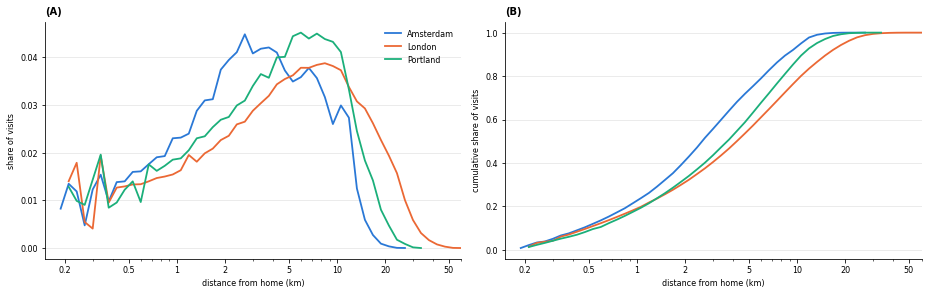

In [5]:
# ── log10 distance bins (0.05 wide) per city ──────────────────────────────────
dist = pd.read_sql(f"""
select city
     , round(floor(log(greatest(dist_home_m, 1)::numeric) * 20) / 20, 2)  as log_bin
     , count(*)                                                as n
from {VISIT} v
group by 1, 2
""", engine)
dist["share"] = dist["n"] / dist.groupby("city")["n"].transform("sum")

# ── plot: share of visits per bin, cumulative share on the right ──────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for city in CITIES:
    d = dist[dist["city"] == city].sort_values("log_bin")
    km = 10 ** (d["log_bin"] + 0.025) / 1000
    axes[0].plot(km, d["share"], color=CITY_COLOR[city], linewidth=1.8, label=CITY_LABEL[city])
    axes[1].plot(km, d["share"].cumsum(), color=CITY_COLOR[city], linewidth=1.8)
for ax, panel, ylab in zip(axes, ["(A)", "(B)"], ["share of visits", "cumulative share of visits"]):
    ax.set_xscale("log")
    ax.set_xlim(0.15, 60)
    ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 20, 50])
    ax.set_xticklabels(["0.2", "0.5", "1", "2", "5", "10", "20", "50"])
    ax.set_xlabel("distance from home (km)", fontsize=FS2)
    ax.set_ylabel(ylab, fontsize=FS2)
    style_axis(ax, panel)
axes[0].legend(frameon=False, fontsize=FS2)
plt.tight_layout()

---
# 3. Activity: places visited grow with tweeting

Per user: active days in the city (any stay, incl. home and work) and distinct visited cells. Raw counts of places
grow almost linearly with activity, so they measure tweeting as much as mobility; places per 10 active days is
nearly flat above ~10 active days (08 V2). (C) shows how concentrated visits are among users, with and without
the automated accounts. Per-user measures come from `revised.visit_user`.

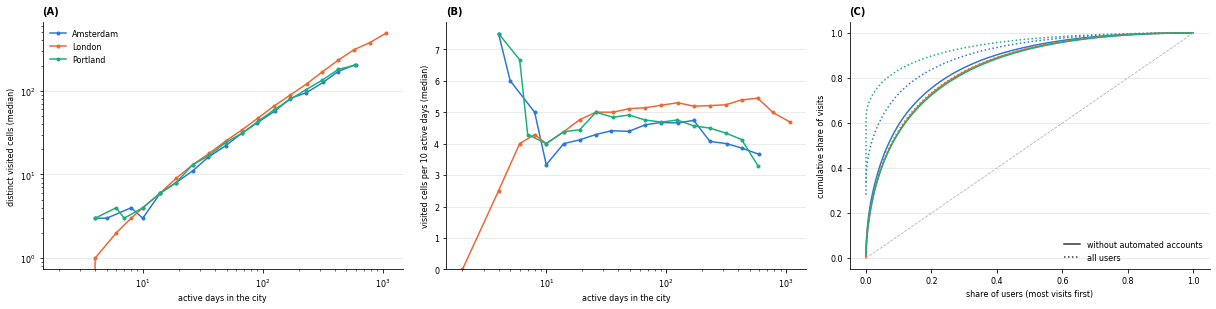

In [6]:
# ── per user: active days, visits, distinct visited cells ─────────────────────
users_all = pd.read_sql("""
select city, d_active, n_visits, n_cells, cells_per_10_days::float as cells_per_10_days, automated
from revised.visit_user
""", engine)
users = users_all[~users_all["automated"]].copy()

# ── binned medians by active days (log bins) ──────────────────────────────────
edges = np.unique(np.round(np.logspace(0, np.log10(users["d_active"].max() + 1), 25)))
users["bin"] = pd.cut(users["d_active"], edges, right=False)
binned = (users.groupby(["city", "bin"], observed=True)
               .agg(d_mid=("d_active", "median"), n_cells=("n_cells", "median"),
                    per10=("cells_per_10_days", "median"), n=("d_active", "size"))
               .reset_index())
binned = binned[binned["n"] >= 30]

# ── plot: (A) distinct cells, (B) cells per 10 active days, (C) concentration ─
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for city in CITIES:
    b = binned[binned["city"] == city]
    axes[0].plot(b["d_mid"], b["n_cells"], marker="o", markersize=3, color=CITY_COLOR[city],
                 label=CITY_LABEL[city])
    axes[1].plot(b["d_mid"], b["per10"], marker="o", markersize=3, color=CITY_COLOR[city])
    for df, ls in [(users, "-"), (users_all, ":")]:
        v = np.sort(df.loc[df["city"] == city, "n_visits"].to_numpy())[::-1]
        axes[2].plot(np.arange(1, len(v) + 1) / len(v), np.cumsum(v) / v.sum(), color=CITY_COLOR[city],
                     linestyle=ls)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("active days in the city", fontsize=FS2)
axes[0].set_ylabel("distinct visited cells (median)", fontsize=FS2)
axes[0].legend(frameon=False, fontsize=FS2)
axes[1].set_xscale("log")
axes[1].set_ylim(0, None)
axes[1].set_xlabel("active days in the city", fontsize=FS2)
axes[1].set_ylabel("visited cells per 10 active days (median)", fontsize=FS2)
axes[2].plot([0, 1], [0, 1], color="0.7", linewidth=0.8, linestyle="--")
axes[2].set_xlabel("share of users (most visits first)", fontsize=FS2)
axes[2].set_ylabel("cumulative share of visits", fontsize=FS2)
axes[2].legend(handles=[Line2D([], [], color="0.2", linestyle="-", label="without automated accounts"),
                        Line2D([], [], color="0.2", linestyle=":", label="all users")],
               frameon=False, fontsize=FS2, loc="lower right")
for ax, panel in zip(axes, PANEL):
    style_axis(ax, panel)
plt.tight_layout()

---
# 4. Maps
## 4.1 Distinct visitors per res 9 cell

Counts of distinct users who visited the cell at least once (not visits). Log colour scale.

In [7]:
# ── distinct visitors and visits per res 9 cell ───────────────────────────────
vmap = read_hex(f"""
select city
     , public.h3_cell_to_parent(cell_10, 9)                         as cell
     , count(distinct user_id)                                     as n_visitors
     , count(*)                                                    as n_visits
     , round(avg((max_point_users is not null)::int)::numeric, 3)  as share_shared_point
from {VISIT} v
group by 1, 2
""")
vmap.groupby("city")["n_visitors"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
amsterdam,3488.0,53.5,147.3,1.0,3.0,13.0,39.0,2280.0
london,22239.0,167.6,597.3,1.0,12.0,44.0,117.0,17824.0
portland,5398.0,55.0,148.1,1.0,6.0,16.0,43.8,2577.0


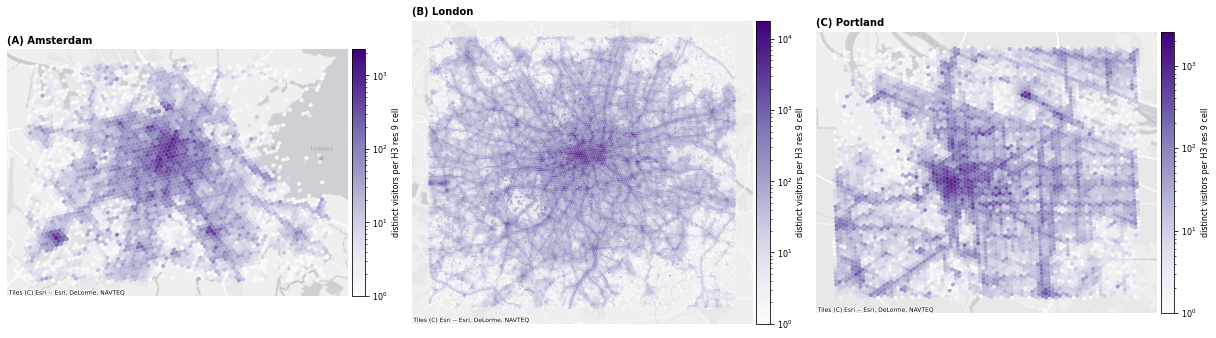

In [8]:
# ── plot: one panel per city ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, city, panel in zip(axes, CITIES, PANEL):
    g = vmap[vmap["city"] == city]
    hex_map(ax, g, "n_visitors", LogNorm(1, g["n_visitors"].max()), "distinct visitors per H3 res 9 cell",
            f"{panel} {CITY_LABEL[city]}", cmap="Purples")
plt.tight_layout()

## 4.2 London centre at res 10, and the share of visits at shared points

Res 10 is the unit amenities will be matched to. (B): share of a cell's visits that fall on a shared coordinate
(used by >= 5 users), mostly check-in venues; cells with >= 20 visitors.

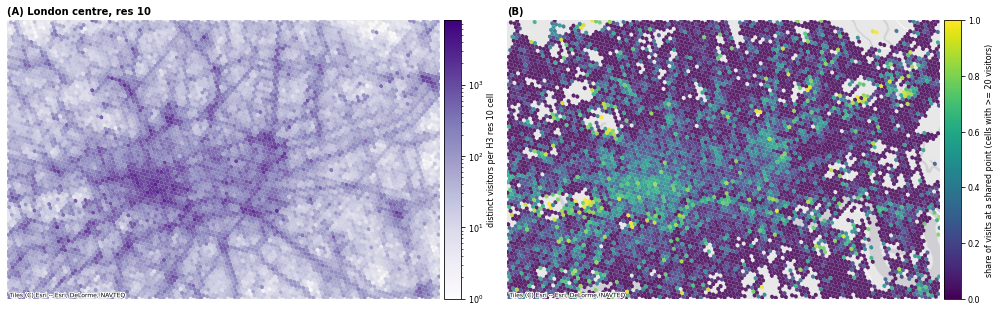

In [9]:
# ── res 10 cells in the London zoom window ────────────────────────────────────
lon0, lat0, lon1, lat1 = ZOOM["london"]
v10 = read_hex(f"""
select cell, n_visitors, share_shared_point
from (
    select cell_10                                                     as cell
         , count(distinct user_id)                                     as n_visitors
         , round(avg((max_point_users is not null)::int)::numeric, 3)  as share_shared_point
    from {VISIT} v
    where city = 'london'
    group by 1
) c
where public.st_x(public.h3_cell_to_geometry(cell)) between {lon0} and {lon1}
  and public.st_y(public.h3_cell_to_geometry(cell)) between {lat0} and {lat1}
""")

# ── plot: (A) visitors, (B) share at shared points ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
hex_map(axes[0], v10, "n_visitors", LogNorm(1, v10["n_visitors"].max()),
        "distinct visitors per H3 res 10 cell", "(A) London centre, res 10",
        extent=zoom_extent("london"), cmap="Purples")
g = v10[v10["n_visitors"] >= 20]
hex_map(axes[1], g, "share_shared_point", plt.Normalize(0, 1),
        "share of visits at a shared point (cells with >= 20 visitors)", "(B)",
        extent=zoom_extent("london"), cmap="viridis")
plt.tight_layout()

## 4.3 Most visited res 10 cells

Top 10 per city by distinct visitors. Expect stations, airports, squares and venues.

In [10]:
# ── top 10 cells per city ─────────────────────────────────────────────────────
pd.read_sql(f"""
select city, cell::text as cell, n_visitors, n_visits, share_shared_point, lat, lon
from (
    select city
         , cell_10                                                          as cell
         , count(distinct user_id)                                          as n_visitors
         , count(*)                                                         as n_visits
         , round(avg((max_point_users is not null)::int)::numeric, 2)       as share_shared_point
         , round(public.st_y(public.h3_cell_to_geometry(cell_10))::numeric, 5) as lat
         , round(public.st_x(public.h3_cell_to_geometry(cell_10))::numeric, 5) as lon
         , row_number() over (partition by city order by count(distinct user_id) desc) as rk
    from {VISIT} v
    group by city, cell_10
) x
where rk <= 10
order by city, rk
""", engine)

,city,cell,n_visitors,n_visits,share_shared_point,lat,lon
0,amsterdam,8a1969512bb7fff,1412,5051,0.85,52.30937,4.76244
1,amsterdam,8a1969c9b16ffff,1043,3114,0.76,52.37823,4.89999
2,amsterdam,8a1969c9b397fff,1042,2210,0.74,52.37303,4.89264
3,amsterdam,8a1969535897fff,979,1959,0.57,52.36426,4.88216
4,amsterdam,8a1969526597fff,971,2018,0.64,52.36621,4.89647
5,amsterdam,8a1969535127fff,943,2138,0.80,52.36231,4.88325
6,amsterdam,8a1969512ba7fff,934,1970,0.86,52.30926,4.76421
7,amsterdam,8a196953589ffff,885,1751,0.61,52.36328,4.88270
8,amsterdam,8a1969c9b167fff,812,1785,0.42,52.37921,4.89944
9,amsterdam,8a1969535887fff,700,1164,0.48,52.36415,4.88393


---
# 5. Timing

Visits by day of week and by local hour of the visit's first tweet (weekdays vs weekends). Third places should lean
to evenings and weekends.

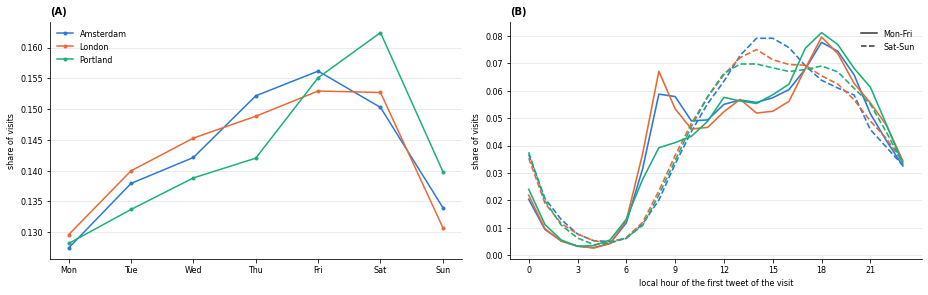

In [11]:
# ── visits by city, day of week and hour ──────────────────────────────────────
vt = pd.read_sql(f"""
select city, dow, extract(hour from first_local)::int as hour, count(*) as n
from {VISIT} v
group by 1, 2, 3
""", engine)

# ── plot: (A) day of week, (B) hour, weekdays solid / weekends dashed ─────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for city in CITIES:
    d = vt[vt["city"] == city]
    by_dow = d.groupby("dow")["n"].sum()
    axes[0].plot(by_dow.index, by_dow / by_dow.sum(), marker="o", markersize=3, color=CITY_COLOR[city],
                 label=CITY_LABEL[city])
    for wd, ls in [(True, "-"), (False, "--")]:
        h = d[(d["dow"] <= 5) == wd].groupby("hour")["n"].sum()
        axes[1].plot(h.index, h / h.sum(), color=CITY_COLOR[city], linestyle=ls, linewidth=1.6)
axes[0].set_xticks(range(1, 8))
axes[0].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[0].set_ylabel("share of visits", fontsize=FS2)
axes[0].legend(frameon=False, fontsize=FS2)
axes[1].set_xticks(range(0, 24, 3))
axes[1].set_xlabel("local hour of the first tweet of the visit", fontsize=FS2)
axes[1].set_ylabel("share of visits", fontsize=FS2)
axes[1].legend(handles=[Line2D([], [], color="0.2", linestyle="-", label="Mon-Fri"),
                        Line2D([], [], color="0.2", linestyle="--", label="Sat-Sun")],
               frameon=False, fontsize=FS2)
style_axis(axes[0], "(A)")
style_axis(axes[1], "(B)")
plt.tight_layout()

---
# 6. Example user (London)

One London user with a `high` home, a work place and a moderate number of visited places (25-60 cells, >= 30 visit
days, not flagged as a suspected bot or automated account). Picked reproducibly by a hash of the id, not by hand. The user id is not
printed. Individual-level map: for internal use only, not for publication.

Home cell (blue outline) and home area (light blue, excluded from visits), work cell (orange outline, excluded),
visited cells coloured by number of visit days. (A) the whole city, (B) zoom on home and work.

In [12]:
# ── pick the user ─────────────────────────────────────────────────────────────
pick = pd.read_sql("""
with cand as (
    select v.user_id
         , count(*)                       as n_visits
         , count(distinct v.cell_10)      as n_cells
         , count(distinct v.local_date)   as n_days
    from revised.visit v
    join revised.home_final h
      on h.city = v.city and h.user_id = v.user_id and h.res = 10
     and h.confidence = 'high' and not h.suspect_bot
    join revised.work_final w
      on w.city = v.city and w.user_id = v.user_id
    join revised.visit_user u
      on u.city = v.city and u.user_id = v.user_id and not u.automated
    where v.city = 'london'
    group by v.user_id
    having count(distinct v.cell_10) between 25 and 60
       and count(distinct v.local_date) >= 30
)
select *
from cand
order by md5(user_id::text)
limit 1
""", engine)
uid = int(pick.loc[0, "user_id"])
pick.drop(columns="user_id")

,n_visits,n_cells,n_days
0,340,54,148


In [13]:
# ── the user's home, home area, work and visited cells ────────────────────────
ex = read_hex(f"""
select 'home' as kind, cell, d_home_nights as n
from revised.home_final
where city = 'london' and user_id = {uid} and res = 10
union all
select 'home_area', cell_10, null
from revised.visit_home_area
where city = 'london' and user_id = {uid}
union all
select 'work', cell, d_work_days
from revised.work_final
where city = 'london' and user_id = {uid}
union all
select 'visit', cell_10, count(*)
from revised.visit
where city = 'london' and user_id = {uid}
group by cell_10
""")
home = ex[ex["kind"] == "home"]
work_c = ex[ex["kind"] == "work"]
vis = ex[ex["kind"] == "visit"].sort_values("n")
print(f"home: {int(home['n'].iloc[0])} nights | work: {int(work_c['n'].iloc[0])} weekdays | "
      f"visits: {int(vis['n'].sum())} on {len(vis)} cells")

home: 51 nights | work: 20 weekdays | visits: 340 on 54 cells


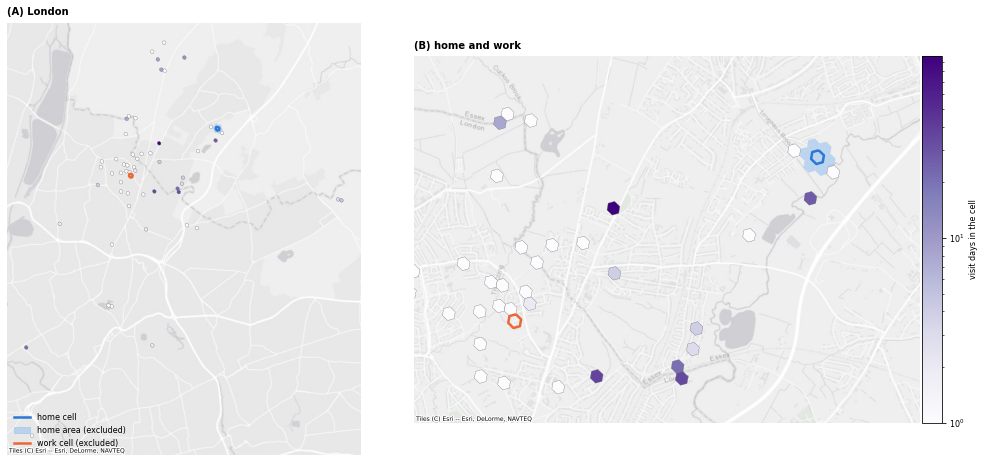

In [14]:
# ── plot: (A) whole city, (B) zoom on home and work ───────────────────────────
norm = LogNorm(1, max(2, vis["n"].max()))
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
hw = pd.concat([home, work_c])
xmin, ymin, xmax, ymax = hw.total_bounds
pad = max(1500, 0.3 * max(xmax - xmin, ymax - ymin))
for ax, panel, extent in [(axes[0], "(A) London", None),
                          (axes[1], "(B) home and work", (xmin - pad, xmax + pad, ymin - pad, ymax + pad))]:
    ex[ex["kind"] == "home_area"].plot(color="#9cc3ef", linewidth=0, alpha=0.6, ax=ax)
    vis.plot(column="n", cmap="Purples", norm=norm, linewidth=0.3, edgecolor="0.4", ax=ax)
    home.boundary.plot(color="#2a78d6", linewidth=2.5, ax=ax)
    work_c.boundary.plot(color="#eb6834", linewidth=2.5, ax=ax)
    if extent is None:
        bx = ex.total_bounds
        extent = (bx[0] - 1000, bx[2] + 1000, bx[1] - 1000, bx[3] + 1000)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, attribution_size=FS4)
    ax.set_axis_off()
    ax.text(0.0, 1.02, panel, transform=ax.transAxes, fontsize=FS, fontweight="bold")
cax = make_axes_locatable(axes[1]).append_axes("right", size="4%", pad=0.05)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap="Purples", norm=norm), cax=cax)
cb.set_label("visit days in the cell", fontsize=FS2)
cb.ax.tick_params(labelsize=FS2)
axes[0].legend(handles=[Line2D([], [], color="#2a78d6", linewidth=2.5, label="home cell"),
                        Patch(color="#9cc3ef", alpha=0.6, label="home area (excluded)"),
                        Line2D([], [], color="#eb6834", linewidth=2.5, label="work cell (excluded)")],
               frameon=False, fontsize=FS2, loc="lower left")
plt.tight_layout()

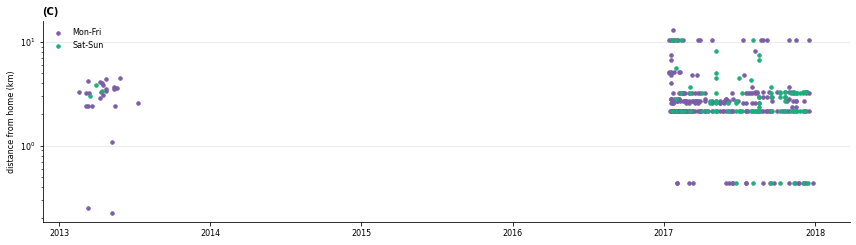

In [15]:
# ── the user's visits over time: distance from home per visit ─────────────────
tl = pd.read_sql(f"""
select local_date, dow, dist_home_m, n_tweets
from revised.visit
where city = 'london' and user_id = {uid}
order by local_date
""", engine, parse_dates=["local_date"])

fig, ax = plt.subplots(figsize=(12, 3.5))
wkend = tl["dow"] >= 6
ax.scatter(tl.loc[~wkend, "local_date"], tl.loc[~wkend, "dist_home_m"] / 1000, s=12, color="#7b5ea7",
           label="Mon-Fri")
ax.scatter(tl.loc[wkend, "local_date"], tl.loc[wkend, "dist_home_m"] / 1000, s=12, color="#1baf7a",
           label="Sat-Sun")
ax.set_yscale("log")
ax.set_ylabel("distance from home (km)", fontsize=FS2)
ax.legend(frameon=False, fontsize=FS2)
style_axis(ax, "(C)")
plt.tight_layout()